# Detector de SPAM com RNN/LSTM
Deep Learning | UFPR

In [8]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

## 1. Carregamento do Dataset SMS Spam

In [ ]:
from pathlib import Path

DATASET_PATH = Path.cwd() / 'data' / 'raw' / 'spam.csv'
if not DATASET_PATH.exists():
    raise FileNotFoundError(
        f'Dataset nao encontrado em {DATASET_PATH}. '\
        'Baixe o spam.csv e coloque em data/raw/ para executar localmente.'
    )

df = pd.read_csv(DATASET_PATH, encoding='ISO-8859-1')
df = df.drop(['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], axis=1)
df.columns = ['labels', 'data']

df['b_labels'] = df['labels'].map({'ham': 0, 'spam': 1})
y = df['b_labels'].values

print(df.head())
print('\nDistribuicao de classes:')
print(df['labels'].value_counts())
print(f'\nTotal de mensagens: {len(df)}')

  labels                                               data  b_labels
0    ham  Go until jurong point, crazy.. Available only ...         0
1    ham                      Ok lar... Joking wif u oni...         0
2   spam  Free entry in 2 a wkly comp to win FA Cup fina...         1
3    ham  U dun say so early hor... U c already then say...         0
4    ham  Nah I don't think he goes to usf, he lives aro...         0

Distribuicao de classes:
labels
ham     4825
spam     747
Name: count, dtype: int64

Total de mensagens: 5572


## 2. Pré-processamento de Texto

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(df['data'], y, test_size=0.33)

num_words = 20000
tokenizer = Tokenizer(num_words=num_words)
tokenizer.fit_on_texts(x_train)

sequences_train = tokenizer.texts_to_sequences(x_train)
sequences_test = tokenizer.texts_to_sequences(x_test)

word2index = tokenizer.word_index
V = len(word2index)
print(f'{V} tokens no vocabulario')

data_train = pad_sequences(sequences_train)
T = data_train.shape[1]
data_test = pad_sequences(sequences_test, maxlen=T)

print('data_train.shape:', data_train.shape)
print('data_test.shape:', data_test.shape)

7162 tokens no vocabulario
data_train.shape: (3733, 189)
data_test.shape: (1839, 189)


## 3. Arquitetura da Rede RNN (Many-to-One)

In [11]:
D = 20  # Dimensao do embedding
M = 5   # Unidades LSTM

i = Input(shape=(T,))
x = Embedding(V + 1, D)(i)            # V+1 para incluir o token de padding (0)
x = LSTM(M)(x)                        # LSTM Many-to-One
x = Dense(1, activation='sigmoid')(x) # Saida binaria

model = Model(i, x)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 189)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ (None, 189, 20)        │       143,260 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 5)              │           520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             6 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 143,786 (561.66 KB)

 Trainable params: 143,786 (561.66 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Compilação e Treinamento

In [12]:
model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

epochs = 5
r = model.fit(
    data_train, y_train,
    epochs=epochs,
    validation_data=(data_test, y_test)
)

Epoch 1/5
117/117 ━━━━━━━━━━━━━━━━━━━━ 9s 63ms/step - accuracy: 0.8711 - loss: 0.4253 - val_accuracy: 0.9173 - val_loss: 0.2491
Epoch 2/5
117/117 ━━━━━━━━━━━━━━━━━━━━ 7s 60ms/step - accuracy: 0.9630 - loss: 0.1796 - val_accuracy: 0.9652 - val_loss: 0.1515
Epoch 3/5
117/117 ━━━━━━━━━━━━━━━━━━━━ 7s 56ms/step - accuracy: 0.9863 - loss: 0.1125 - val_accuracy: 0.9788 - val_loss: 0.1086
Epoch 4/5
117/117 ━━━━━━━━━━━━━━━━━━━━ 11s 64ms/step - accuracy: 0.9917 - loss: 0.0774 - val_accuracy: 0.9793 - val_loss: 0.0881
Epoch 5/5
117/117 ━━━━━━━━━━━━━━━━━━━━ 6s 53ms/step - accuracy: 0.9949 - loss: 0.0544 - val_accuracy: 0.9831 - val_loss: 0.0741


## 5. Avaliação

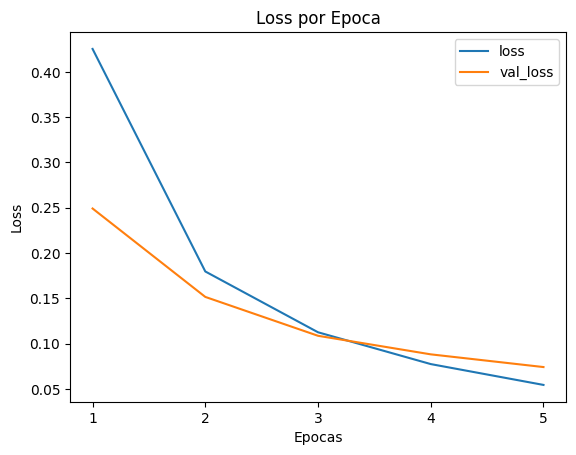

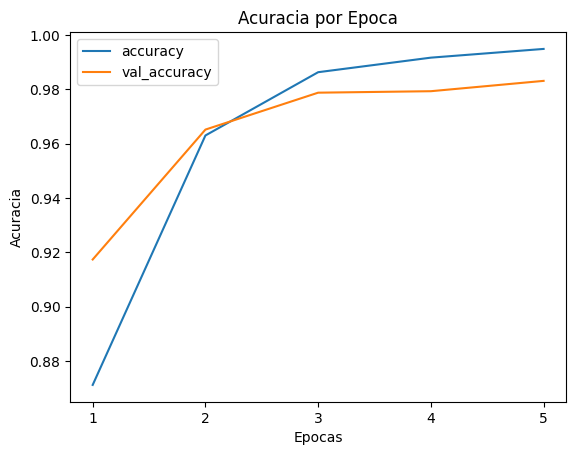

In [13]:
# Curva de Loss
plt.plot(r.history['loss'], label='loss')
plt.plot(r.history['val_loss'], label='val_loss')
plt.xlabel('Epocas')
plt.ylabel('Loss')
plt.xticks(np.arange(0, epochs, step=1), labels=range(1, epochs + 1))
plt.legend()
plt.title('Loss por Epoca')
plt.show()

# Curva de Acuracia
plt.plot(r.history['accuracy'], label='accuracy')
plt.plot(r.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epocas')
plt.ylabel('Acuracia')
plt.xticks(np.arange(0, epochs, step=1), labels=range(1, epochs + 1))
plt.legend()
plt.title('Acuracia por Epoca')
plt.show()

In [14]:
def predict_spam(texto):
    seq = tokenizer.texts_to_sequences([texto])
    data = pad_sequences(seq, maxlen=T)
    pred = model.predict(data, verbose=0)[0][0]
    resultado = 'SPAM' if pred >= 0.5 else 'HAM (OK)'
    print(f'Mensagem: "{texto[:80]}..."' if len(texto) > 80 else f'Mensagem: "{texto}"')
    print(f'Score: {pred:.4f} -> {resultado}\n')
    return pred

# Exemplos
predict_spam("Is your car dirty? Discover our new product. Free for all. Click the link.")
predict_spam("Hi, my name is Razer and want to tell you something.")
predict_spam("WINNER!! As a valued network customer you have been selected to receive a €900 prize reward!")
predict_spam("Ok lar... Joking wif u oni...")

Mensagem: "Is your car dirty? Discover our new product. Free for all. Click the link."
Score: 0.6954 -> SPAM

Mensagem: "Hi, my name is Razer and want to tell you something."
Score: 0.0144 -> HAM (OK)

Mensagem: "WINNER!! As a valued network customer you have been selected to receive a €900 p..."
Score: 0.8114 -> SPAM

Mensagem: "Ok lar... Joking wif u oni..."
Score: 0.0153 -> HAM (OK)



np.float32(0.015293861)